# 1. Installing Dependencies

In [2]:
!pip install -q sentence-transformers rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 34.6 MB/s eta 0:00:00a 0:00:01


# 2. Imports and Configuration

In [3]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from sentence_transformers import SentenceTransformer
from rapidfuzz.fuzz import ratio, WRatio

import cv2
from IPython.display import display, Image

In [27]:
# Qwen results dataset
QWEN_RESULTS_DIR = Path("/kaggle/input/datasets/pavirajindra/quest1-qwen-results")

# Original video dataset
VIDEO_DIR = Path("/kaggle/input/datasets/pavirajindra/quest1-video")
WORKING_DIR = Path("/kaggle/working")

INPUT_VIDEO_PATH = VIDEO_DIR / "video.mp4"

TRANSCRIPT_PATH = (QWEN_RESULTS_DIR / "qwen_transcript.json")
FRAME_PATH = (WORKING_DIR / "approach2_dialogue_frame.jpg")

print("Video:", INPUT_VIDEO_PATH)
print("Transcript:", TRANSCRIPT_PATH)

Video: /kaggle/input/datasets/pavirajindra/quest1-video/video.mp4
Transcript: /kaggle/input/datasets/pavirajindra/quest1-qwen-results/qwen_transcript.json


# 3. Load the Qwen transcript

In [5]:
with open(TRANSCRIPT_PATH,"r",encoding="utf-8") as f:
    qwen_transcript = json.load(f)

print("Number of timestamped entries:", len(qwen_transcript))
print("\nFirst 10:")
for item in qwen_transcript[:10]:
    print(item)

Number of timestamped entries: 4435

First 10:
{'text': 'But', 'start_ms': 116240, 'end_ms': 116400, 'chunk_index': 2}
{'text': 'Mum', 'start_ms': 116400, 'end_ms': 117040, 'chunk_index': 2}
{'text': 'close', 'start_ms': 117680, 'end_ms': 118000, 'chunk_index': 2}
{'text': 'the', 'start_ms': 118000, 'end_ms': 118080, 'chunk_index': 2}
{'text': 'window', 'start_ms': 118080, 'end_ms': 118320, 'chunk_index': 2}
{'text': 'John', 'start_ms': 118400, 'end_ms': 118400, 'chunk_index': 2}
{'text': 'To', 'start_ms': 118480, 'end_ms': 118640, 'chunk_index': 2}
{'text': 'Sherlock', 'start_ms': 138240, 'end_ms': 138800, 'chunk_index': 2}
{'text': 'Holmes', 'start_ms': 138800, 'end_ms': 139520, 'chunk_index': 2}
{'text': 'she', 'start_ms': 139760, 'end_ms': 139920, 'chunk_index': 2}


# 4. Normalize text

In [6]:
def normalize_text(text):
    text = text.lower()
    text = text.replace("’", "'")
    text = re.sub(r"[^\w\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# 5. Build transcript windows

In [7]:
def build_transcript_windows(transcript, window_size=30, stride=10):
    windows = []
    n = len(transcript)

    for start_idx in range(0, n, stride):
        end_idx = min(start_idx + window_size, n)
        words = transcript[start_idx:end_idx]

        if not words:
            continue

        text = " ".join(item["text"] for item in words)

        windows.append({
            "start_index": start_idx,
            "end_index": end_idx,
            "text": text,
            "normalized_text": normalize_text(text),
            "start_ms": words[0]["start_ms"],
            "end_ms": words[-1]["end_ms"]
        })

        if end_idx == n:
            break

    return windows

In [8]:
transcript_windows = build_transcript_windows(qwen_transcript, window_size=30, stride=10)

print("Number of transcript windows:", len(transcript_windows))

for window in transcript_windows[:3]:
    print(f"\n{window['start_ms']} → {window['end_ms']}")
    print(window["text"])

Number of transcript windows: 442

116240 → 168400
But Mum close the window John To Sherlock Holmes she was always the woman the beautiful Irina Adler of dubious and questionable memory At the time of our involvement in

139920 → 168040
was always the woman the beautiful Irina Adler of dubious and questionable memory At the time of our involvement in the Irina Adler case At the time of our involvement

146960 → 172200
and questionable memory At the time of our involvement in the Irina Adler case At the time of our involvement in the Irene Adler case Holmes and I had been


# 6. Load the embedding model

In [9]:
EMBEDDING_MODEL_NAME = ("sentence-transformers/all-mpnet-base-v2")

embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME,device="cuda" if torch.cuda.is_available() else "cpu")

print("Embedding model loaded.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded.


# 7. Generate transcript embeddings

In [10]:
window_texts = [window["normalized_text"] for window in transcript_windows]

window_embeddings = embedding_model.encode(
    window_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embedding shape:",window_embeddings.shape)

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Embedding shape: (442, 768)


# 8. Function to search semantically

In [11]:
def semantic_search(query, top_k=10):
    query_normalized = normalize_text(query)

    query_embedding = embedding_model.encode(
        [query_normalized],
        convert_to_numpy=True,
        normalize_embeddings=True
    )[0]

    similarities = window_embeddings @ query_embedding
    top_indices = np.argsort(similarities)[::-1][:top_k]

    results = []

    for idx in top_indices:
        result = transcript_windows[idx].copy()
        result["semantic_score"] = float(similarities[idx])
        result["window_index"] = int(idx)
        results.append(result)

    return results

# 9. Test semantic search

In [12]:
QUERY = "My mind rebels if it becomes stagnant"

In [13]:
semantic_results = semantic_search(QUERY, top_k=10)

for i, result in enumerate(semantic_results, start=1):
    print(f"\nRank {i}")
    print(f"Semantic score: {result['semantic_score']:.4f}")
    print(f"Timestamp: {result['start_ms']} → {result['end_ms']} ms")
    print(f"Text: {result['text']}")


Rank 1
Semantic score: 0.6172
Timestamp: 316440 → 330960 ms
Text: cannot tell you how it clarifies and stimulates the mind Yes and destroys it in time My mind rebels at stagnation Give me problems Give me work Give me problems

Rank 2
Semantic score: 0.5701
Timestamp: 319000 → 336640 ms
Text: Yes and destroys it in time My mind rebels at stagnation Give me problems Give me work Give me problems Give me work Give me the most abstruse cryptogram the

Rank 3
Semantic score: 0.5102
Timestamp: 336640 → 356320 ms
Text: most intricate analysis and I'm in my proper atmosphere Then I can dispense with artificial stimulants But I abhor the dull routine of existence I crave mental exaltation That is

Rank 4
Semantic score: 0.4663
Timestamp: 326680 → 342000 ms
Text: stagnation Give me problems Give me work Give me problems Give me work Give me the most abstruse cryptogram the most intricate analysis and I'm in my proper atmosphere Then

Rank 5
Semantic score: 0.4538
Timestamp: 342000 → 359600 ms


# 10. Fuzzy / edit-distance similarity

In [15]:
def fuzzy_score(query, candidate):
    return ratio(
        normalize_text(query),
        normalize_text(candidate)
    ) / 100.0

# 11. Combined semantic + fuzzy search

In [17]:
def combined_search(
    query,
    top_k=10,
    semantic_weight=0.7,
    fuzzy_weight=0.3
):
    all_results = semantic_search(query, top_k=len(transcript_windows))

    for result in all_results:
        result["fuzzy_score"] = fuzzy_score(query, result["text"])
        result["combined_score"] = (
            semantic_weight * result["semantic_score"]
            + fuzzy_weight * result["fuzzy_score"]
        )

    all_results.sort(
        key=lambda x: x["combined_score"],
        reverse=True
    )

    return all_results[:top_k]

# 12. Run combined retrieval

In [18]:
results = combined_search(QUERY, top_k=10)

for rank, result in enumerate(results, start=1):
    print("\n" + "=" * 70)
    print(f"Rank: {rank}")
    print(f"Semantic score: {result['semantic_score']:.4f}")
    print(f"Fuzzy score: {result['fuzzy_score']:.4f}")
    print(f"Combined score: {result['combined_score']:.4f}")
    print(f"Window timestamp: {result['start_ms']} → {result['end_ms']} ms")
    print(f"Text: {result['text']}")


Rank: 1
Semantic score: 0.6172
Fuzzy score: 0.2741
Combined score: 0.5143
Window timestamp: 316440 → 330960 ms
Text: cannot tell you how it clarifies and stimulates the mind Yes and destroys it in time My mind rebels at stagnation Give me problems Give me work Give me problems

Rank: 2
Semantic score: 0.5701
Fuzzy score: 0.3299
Combined score: 0.4980
Window timestamp: 319000 → 336640 ms
Text: Yes and destroys it in time My mind rebels at stagnation Give me problems Give me work Give me problems Give me work Give me the most abstruse cryptogram the

Rank: 3
Semantic score: 0.5102
Fuzzy score: 0.2791
Combined score: 0.4409
Window timestamp: 336640 → 356320 ms
Text: most intricate analysis and I'm in my proper atmosphere Then I can dispense with artificial stimulants But I abhor the dull routine of existence I crave mental exaltation That is

Rank: 4
Semantic score: 0.4663
Fuzzy score: 0.2871
Combined score: 0.4126
Window timestamp: 326680 → 342000 ms
Text: stagnation Give me problems Gi

# 13. Fine-grained matching

In [19]:
def fine_grained_search(query, candidate, max_extra_words=10):
    query_words = normalize_text(query).split()
    query_length = len(query_words)

    search_start = max(0, candidate["start_index"] - max_extra_words)
    search_end = min(
        len(qwen_transcript),
        candidate["end_index"] + max_extra_words
    )

    candidates = []

    min_length = max(1, query_length - max_extra_words)
    max_length = query_length + max_extra_words

    for start in range(search_start, search_end):
        for length in range(min_length, max_length + 1):
            end = start + length

            if end > len(qwen_transcript):
                continue

            words = qwen_transcript[start:end]
            text = " ".join(word["text"] for word in words)
            score = fuzzy_score(query, text)

            candidates.append({
                "text": text,
                "start_index": start,
                "end_index": end,
                "start_ms": words[0]["start_ms"],
                "end_ms": words[-1]["end_ms"],
                "fuzzy_score": score
            })

    candidates.sort(
        key=lambda x: x["fuzzy_score"],
        reverse=True
    )

    return candidates

# 14. Find exact dialogue region

In [20]:
best_coarse_match = results[0]

fine_results = fine_grained_search(QUERY, best_coarse_match)
best_match = fine_results[0]

print("Best dialogue match:")
print("\nInput:")
print(QUERY)
print("\nMatched:")
print(best_match["text"])
print("\nStart:", best_match["start_ms"], "ms")
print("End:", best_match["end_ms"], "ms")
print("Fuzzy score:", f"{best_match['fuzzy_score']:.4f}")

Best dialogue match:

Input:
My mind rebels if it becomes stagnant

Matched:
My mind rebels at stagnation

Start: 325240 ms
End: 327320 ms
Fuzzy score: 0.7385


# 15. Timestamp formatting

In [21]:
def format_timestamp(milliseconds):
    total_seconds = milliseconds / 1000
    hours = int(total_seconds // 3600)
    minutes = int((total_seconds % 3600) // 60)
    seconds = total_seconds % 60

    return f"{hours:02d}:{minutes:02d}:{seconds:06.3f}"

In [23]:
print(format_timestamp(best_match["start_ms"]))

00:05:25.240


# 16. Get Video Frame

In [24]:
cap = cv2.VideoCapture(str(INPUT_VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Could not open video.")

FPS = cap.get(cv2.CAP_PROP_FPS)
TOTAL_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
VIDEO_DURATION = TOTAL_FRAMES / FPS

cap.release()

print(f"FPS: {FPS}")
print(f"Total frames: {TOTAL_FRAMES}")
print(f"Duration: {VIDEO_DURATION:.3f} seconds")

FPS: 23.97616608930767
Total frames: 78204
Duration: 3261.739 seconds


In [25]:
def extract_frame(video_path, timestamp_ms, output_path):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError("Could not open video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_number = int(round(timestamp_ms / 1000 * fps))

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    success, frame = cap.read()
    cap.release()

    if not success:
        raise RuntimeError(f"Could not extract frame {frame_number}")

    cv2.imwrite(str(output_path), frame)

    return frame_number, fps

In [28]:
frame_number, fps = extract_frame(
    INPUT_VIDEO_PATH,
    best_match["start_ms"],
    FRAME_PATH
)

print("Frame number:", frame_number)
print("FPS:", fps)
print("Frame path:", FRAME_PATH)

Frame number: 7798
FPS: 23.97616608930767
Frame path: /kaggle/working/approach2_dialogue_frame.jpg


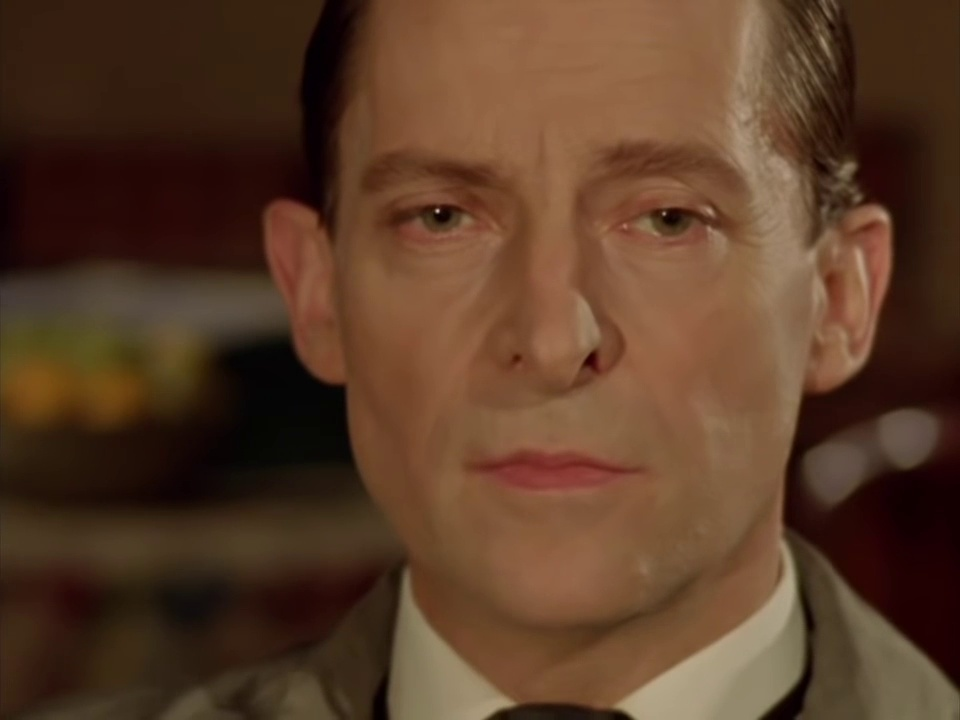

In [30]:
display(Image(filename=str(FRAME_PATH)))

# 17. Final Result

In [31]:
final_result = {
    "input_dialogue": QUERY,
    "matched_dialogue": best_match["text"],
    "timestamp": format_timestamp(best_match["start_ms"]),
    "start_ms": best_match["start_ms"],
    "end_ms": best_match["end_ms"],
    "frame_number": frame_number,
    "fps": fps,
    "frame_path": str(FRAME_PATH),
    "semantic_score": best_coarse_match["semantic_score"],
    "fuzzy_score": best_match["fuzzy_score"],
    "combined_score": best_coarse_match["combined_score"]
}

In [32]:
import pprint

pprint.pprint(final_result)

{'combined_score': 0.5143025538037876,
 'end_ms': 327320,
 'fps': 23.97616608930767,
 'frame_number': 7798,
 'frame_path': '/kaggle/working/approach2_dialogue_frame.jpg',
 'fuzzy_score': 0.7384615384615385,
 'input_dialogue': 'My mind rebels if it becomes stagnant',
 'matched_dialogue': 'My mind rebels at stagnation',
 'semantic_score': 0.6172415018081665,
 'start_ms': 325240,
 'timestamp': '00:05:25.240'}


In [33]:
OUTPUT_JSON = WORKING_DIR / "approach2_result.json"

with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(final_result, f, ensure_ascii=False, indent=2)

print("Saved:", OUTPUT_JSON)

Saved: /kaggle/working/approach2_result.json


---